# Key results from the thesis

The original goal of this thesis was to assess the cross-simulation robustness of Neural Posterior Estimation (NPE). Our results show that it depends on the feature. Some features transfer well across simulations, whilst others risk the model producing overconfident posteriors and losing calibration when transferring.

The main findings are that stellar velocity dispersion and absolute stellar mass improve within-simulation prediction but are sensitive to simulation transfer; a training-calibrated stellar normalization shift removes much of the stellar-model bias; and the observed Local Group estimates remain simulation-dependent. This notebook collects the key numbers from the thesis's Results and Discussion chapters. It uses the small result tables included in the repository and does not train or load a model.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(name):
    return pd.read_csv(ROOT / 'results' / name)
def record(name):
    return json.loads((ROOT / 'results' / name).read_text(encoding='utf-8'))

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
counts = table('populations/pair_counts.csv').set_index('domain')
assert counts['n'].to_dict() == {'flamingo': 142713, 'tng': 1530}
ks = record('bootstrap/population_reference.json')['theta_marginal']
assert np.isclose(ks['p_value'], 1 / 501)
display(counts.rename(columns={'n':'Pairs','same_host':'Same-host','different_host':'Different-host',
                              'median_log_mass':'Median log10 mass'}).round(3))
display(Markdown(f"The target-mass distributions differ by **{counts.loc['tng','median_log_mass']-counts.loc['flamingo','median_log_mass']:.3f} dex** in their medians. The observed KS statistic is **{ks['ks_real']:.4f}**. None of 500 TNG-sized FLAMINGO subsamples reaches it: the plus-one reference p value is **1/501 ≈ {ks['p_value']:.3f}**."))
refits = table('bootstrap/posterior_subsampling_repeats.csv')
refits = refits.loc[refits.block == 'core_dynamics', 'jsd_vs_full'].to_numpy()
observed_jsd = record('bootstrap/observed_jsd.json')['core_dynamics']['jsd_full']
core_jsd_p = (1 + np.count_nonzero(refits >= observed_jsd)) / (len(refits) + 1)
assert len(refits) == 200 and np.isclose(core_jsd_p, 51/201)


,Pairs,Same-host,Different-host,Median log10 mass
domain,,,,
flamingo,142713,63071,79642,12.401
tng,1530,1253,277,12.645


The target-mass distributions differ by **0.244 dex** in their medians. The observed KS statistic is **0.3064**. None of 500 TNG-sized FLAMINGO subsamples reaches it: the plus-one reference p value is **1/501 ≈ 0.002**.

## Better prediction within one simulation does not guarantee transfer

The populations differ in target mass and host composition, and the population KS result is inconsistent with the tested sample-size reference. Posterior-subsampling and ablation references answer different questions: the separate core-dynamics JSD comparison is consistent with its refit reference (p ≈ 0.254), whereas the ablation discrepancies reach the 1/201 resolution floor. This does not model cosmic variance or identify a physical cause.

The feature-block experiment starts with separation, peculiar radial velocity, tangential velocity and the log **bound-subhalo mass ratio**. Morphology adds pair means and differences of stellar velocity dispersion and κcorot. Its FLAMINGO R² rises to 0.922, but falls to 0.612 on the 231 TNG test pairs. The all-features model falls from 0.926 to 0.558.

Removing stellar velocity dispersion reduces the morphology posterior discrepancy from 0.1887 to 0.1162 dex, a 38.4% reduction. Removing κcorot does not have a similar effect. Supporting calibration on all 1530 TNG pairs improves central 68% coverage from 14.8% to 65.8% when dispersion is removed. The ablation identifies an influential input; it does not establish feedback as the cause.

Sources: [block transfer](../results/cross/block_transfer_test.csv), [ablation](../results/ablation/ablation_posterior_discrepancy.csv), [supporting calibration](../results/ablation/supporting_calibration_all1530.csv). Details: [feature diagnostics and ablation](07_feature_diagnostics_and_ablation.ipynb).

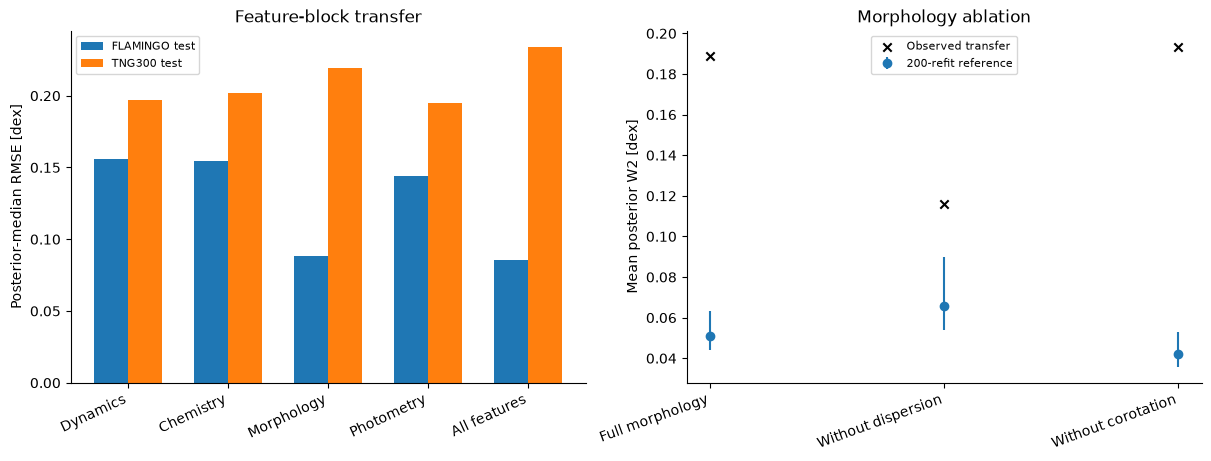

,key,n_test,coverage68,coverage95,bias
0,core_dynamics__full,1530,0.644,0.879,-0.108
1,core_morphology__full,1530,0.148,0.446,-0.194
2,morphology_no_sigma__full,1530,0.658,0.903,-0.092


In [2]:
block = table('cross/block_transfer_test.csv').set_index('block')
ablation = table('ablation/ablation_posterior_discrepancy.csv').set_index('variant')
assert np.isclose(block.loc['core_morphology','within_r2'], .921562, atol=1e-6)
assert np.isclose(block.loc['core_morphology','transfer_r2'], .611857, atol=1e-6)
reduction = 1 - ablation.loc['morphology_no_sigma','mean_w2'] / ablation.loc['core_morphology','mean_w2']
assert np.isclose(reduction, .3844, atol=1e-4)
assert np.allclose(ablation.exceedance_fraction, 1/201)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
labels = ['Dynamics', 'Chemistry', 'Morphology', 'Photometry', 'All features']
x = np.arange(len(block))
axes[0].bar(x-.17, block.within_rmse, width=.34, label='FLAMINGO test')
axes[0].bar(x+.17, block.transfer_rmse, width=.34, label='TNG300 test')
axes[0].set_xticks(x, labels, rotation=25, ha='right')
axes[0].set(ylabel='Posterior-median RMSE [dex]', title='Feature-block transfer')
axes[0].legend(fontsize=8)
variants = ['core_morphology','morphology_no_sigma','morphology_no_kappa']
a = ablation.loc[variants]
x = np.arange(len(a))
axes[1].errorbar(x, a.reference_median,
    yerr=np.vstack([a.reference_median-a.reference_lower, a.reference_upper-a.reference_median]),
    fmt='o', label='200-refit reference')
axes[1].scatter(x, a.mean_w2, marker='x', color='black', label='Observed transfer')
axes[1].set_xticks(x, ['Full morphology','Without dispersion','Without corotation'], rotation=20, ha='right')
axes[1].set(ylabel='Mean posterior W2 [dex]', title='Morphology ablation')
axes[1].legend(fontsize=8, loc='upper center')
plt.show()
display(table('ablation/supporting_calibration_all1530.csv')[['key','n_test','coverage68','coverage95','bias']].round(3))

## Absolute stellar mass makes transfer bias much worse

The six final models use **dynamics = [r, vr, vt]**, with or without `log10(Mstar,a + Mstar,b)`. This dynamics definition omits the bound-mass ratio used in the feature-block experiment. The three training populations are FLAMINGO, TNG300 and an equal-domain combined sample.

Adding stellar sum reduces in-domain RMSE from 0.2343 to 0.1316 dex in FLAMINGO and from 0.3038 to 0.1487 dex in TNG300. Across simulations, however, the stellar-sum bias is −0.3164 dex for FLAMINGO→TNG300 and +0.3214 dex for TNG300→FLAMINGO. Central 68% intervals cover only 19.9% and 10.1% of the true masses, respectively. RMSE alone therefore does not tell the complete story.

The combined model reduces some transfer errors, but residual biases remain. On the 48 different-host TNG test pairs, the FLAMINGO stellar-sum model has zero 68% coverage. Pooled performance should not be assumed to represent this small Local Group-like stratum.

Sources: [six-model metrics](../results/final_six/six_model_metrics.csv). Details: [transfer](04_within_and_cross_simulation.ipynb) and [calibration](05_calibration.ipynb).

,model,domain,n,rmse,bias,r2,68% coverage [%],95% coverage [%]
0,combined_dynamics,flamingo,21409,0.263,0.087,0.308,74.726,95.759
1,combined_dynamics,tng,231,0.319,-0.072,0.178,73.160,91.775
2,combined_stellar_sum,flamingo,21409,0.189,0.095,0.643,71.283,94.979
3,combined_stellar_sum,tng,231,0.208,-0.122,0.649,64.069,90.043
4,flamingo_dynamics,flamingo,21409,0.234,-0.003,0.450,72.839,94.054
5,flamingo_dynamics,tng,231,0.365,-0.155,-0.081,64.935,85.281
6,flamingo_stellar_sum,flamingo,21409,0.132,-0.002,0.826,69.634,94.713
7,flamingo_stellar_sum,tng,231,0.360,-0.316,-0.050,19.913,49.784
8,tng_dynamics,flamingo,21409,0.334,0.195,-0.119,60.456,94.021
9,tng_dynamics,tng,231,0.304,-0.006,0.253,71.861,93.939


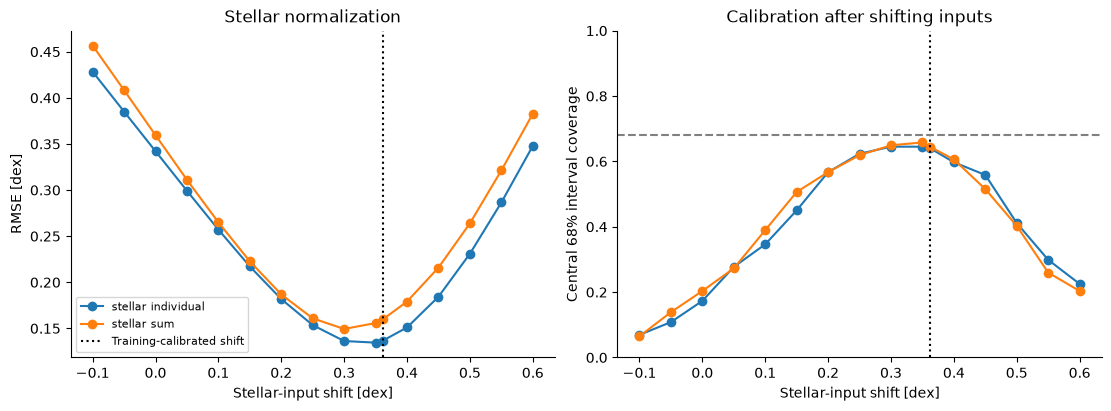

In [3]:
metrics = table('final_six/six_model_metrics.csv')
pooled = metrics.query("subset == 'pooled'").copy()
def metric(model, domain):
    return pooled.loc[(pooled.model == model) & (pooled.domain == domain)].iloc[0]
assert np.isclose(metric('flamingo_dynamics','flamingo').rmse, .234264, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','flamingo').rmse, .131649, atol=1e-6)
assert np.isclose(metric('tng_dynamics','tng').rmse, .303766, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','tng').rmse, .148660, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','tng').bias, -.316399, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','flamingo').bias, .321360, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','tng').coverage68, .199134, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','flamingo').coverage68, .100892, atol=1e-6)
diff = metrics.query("model == 'flamingo_stellar_sum' and domain == 'tng' and subset == 'different_host'").iloc[0]
assert diff.n == 48 and diff.coverage68 == 0
show = pooled[['model','domain','n','rmse','bias','r2','coverage68','coverage95']].copy()
show[['coverage68','coverage95']] *= 100
show = show.rename(columns={'coverage68':'68% coverage [%]','coverage95':'95% coverage [%]'})
display(show.round(3).reset_index(drop=True))

# The shift experiment uses separate stellar-sum and individual-stellar checkpoints.
cal = record('competing/delta_calibration.json')
assert np.isclose(cal['delta'], .36168937856918487)
shift = table('competing/delta_full_sensitivity.csv').query("subset == 'pooled'")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for model, part in shift.groupby('model'):
    part = part.sort_values('delta')
    axes[0].plot(part.delta, part.rmse, 'o-', label=model.replace('_',' '))
    axes[1].plot(part.delta, part.coverage68, 'o-', label=model.replace('_',' '))
for ax in axes:
    ax.axvline(cal['delta'], color='black', ls=':', label='Training-calibrated shift')
    ax.set_xlabel('Stellar-input shift [dex]')
axes[0].set(ylabel='RMSE [dex]', title='Stellar normalization')
axes[1].set(ylabel='Central 68% interval coverage', ylim=(0, 1), title='Calibration after shifting inputs')
axes[1].axhline(.68, color='gray', ls='--')
axes[0].legend(fontsize=8)
plt.show()

## Stellar normalization removes much of the measured bias; common support does not remove it

A training-only regression of summed bound mass gives a calibrated stellar-input shift of **+0.3617 dex**, with component-bootstrap 95% interval **[0.3527, 0.3693]**. On the same 231 TNG test pairs, the separate stellar-sum checkpoint improves from RMSE 0.3595 to 0.1599 dex, while the individual-stellar checkpoint improves from 0.3422 to 0.1368 dex. The shift is applied before feature scaling and was not selected by minimizing held-out M200c error. It is a sensitivity test, not a correction to measured Local Group stellar masses.

The common-support experiment uses balanced, grouped out-of-fold domain scores. Restricting to 0.4≤s(x)≤0.6 retains 311 of all 1530 TNG pairs for stellar sum. RMSE changes from 0.3485 to 0.3708 dex and bias from −0.3036 to −0.3214 dex: the disagreement persists within this operational overlap band. These follow-up populations and checkpoints differ from the six-model 231-row comparison above. Morphology was not tested with common support.

Changing the target to summed bound subhalo mass also leaves large absolute-stellar biases: the stellar-sum variant has RMSE 0.3843 dex, bias −0.3628 dex and 68% coverage of 1.6% on all 1530 TNG pairs. Training-prior swaps reduce forward dynamics bias but leave large stellar-sum biases and are sensitive to bandwidth or low effective sample size in some directions. The declared [11.5,14.5] log-mass box restricts sampling; the empirical simulation mass distributions supply the effective training priors. Together, the tests support a normalization-related explanation, whilst not uniquely separating prior, conditional, physical and selection differences.

Sources: [stellar-shift comparison](../results/competing/delta_zero_and_calibrated.csv), [common support](../results/competing/common_support_main.csv), [alternative target](../results/competing/alternative_target.csv), [prior swaps](../results/prior/prior_swap_main_table.csv). Details: notebooks [08](08_alternative_mass_targets.ipynb), [09](09_stellar_normalization.ipynb), [10](10_common_support.ipynb) and [11](11_prior_and_support_sensitivity.ipynb).

In [4]:
shift_summary = table('competing/delta_zero_and_calibrated.csv').query("subset == 'pooled'")
assert np.isclose(shift_summary.query("model == 'stellar_sum' and calibrated").iloc[0].rmse, .159866, atol=1e-6)
assert np.isclose(shift_summary.query("model == 'stellar_individual' and calibrated").iloc[0].rmse, .136754, atol=1e-6)
display(shift_summary[['model','delta','n','rmse','bias','coverage68','coverage95']].round(3).reset_index(drop=True))
common = table('competing/common_support_main.csv')
common = common.query("population == 'transfer_tng' and feature_space in ['dynamics','stellar_individual','stellar_sum']")
assert set(common.n_total) == {1530}
stellar_overlap = common.query("feature_space == 'stellar_sum' and half_width == .1").iloc[0]
assert stellar_overlap.n == 311 and np.isclose(stellar_overlap.bias, -.321432, atol=1e-6)
display(common[['feature_space','score_interval','n','rmse','bias','coverage68']].round(3).reset_index(drop=True))
prior = table('prior/prior_swap_main_table.csv')
prior = prior.query("model == 'flamingo_stellar_sum'")
display(prior[['model','treatment','n','rmse','bias','coverage68','ess_median','ess_min']].round(3).reset_index(drop=True))
alt = table('competing/alternative_target.csv')
alt_stellar = alt.loc[alt.mass_feature == 'stellar_sum'].iloc[0]
assert alt_stellar.n == 1530 and np.isclose(alt_stellar.bias, -.3628, atol=1e-4)
assert np.isclose(alt_stellar.coverage68, .016, atol=.001)


,model,delta,n,rmse,bias,coverage68,coverage95
0,stellar_sum,0.000,231,0.360,-0.316,0.203,0.541
1,stellar_sum,0.362,231,0.160,0.043,0.645,0.922
2,stellar_individual,0.000,231,0.342,-0.301,0.173,0.537
3,stellar_individual,0.362,231,0.137,0.025,0.641,0.935


,feature_space,score_interval,n,rmse,bias,coverage68
0,dynamics,0.40-0.60,957,0.377,-0.157,0.670
1,dynamics,all,1530,0.368,-0.153,0.667
2,stellar_individual,0.40-0.60,298,0.342,-0.296,0.191
3,stellar_individual,all,1530,0.331,-0.289,0.198
4,stellar_sum,0.40-0.60,311,0.371,-0.321,0.186
5,stellar_sum,all,1530,0.348,-0.304,0.210


,model,treatment,n,rmse,bias,coverage68,ess_median,ess_min
0,flamingo_stellar_sum,original,231,0.360,-0.316,0.199,500.000,500.000
1,flamingo_stellar_sum,prior_swap,231,0.307,-0.249,0.316,396.042,189.241


## The Local Group estimates remain simulation-dependent

Dynamics-only estimates agree closely, with nominal medians of approximately **3.0–3.2×10¹² solar masses**, but their posteriors are broad. Adding stellar mass leaves FLAMINGO near **3.0×10¹²**, moves TNG300 to **5.6×10¹²**, and gives a combined median near **3.2×10¹²**. The specialist median gap grows from 0.037 dex to 0.274 dex. Approximate propagation of input uncertainty changes the medians by less than 0.009 dex, much less than the stellar-conditioned disagreement.

The nominal estimates contain 100000 posterior draws. Input mixtures average 20 conditional draws for each of 5000 independently sampled observational realizations. They approximate uncertainty propagation rather than exact observational marginalization. Observed stellar proxies and all-bound catalogue stellar masses also have different definitions.

The networks do not condition on host membership: same-host pairs use a common host M200c and different-host pairs use the sum of two host masses. The real MW–M31 system is different-host. Pooled feature support does not establish support for that intended two-host inference.

Source: [Local Group posterior summary](../results/local_group/local_group_posterior_summary.csv). Details: [Local Group and interpretation](12_local_group_and_interpretation.ipynb).

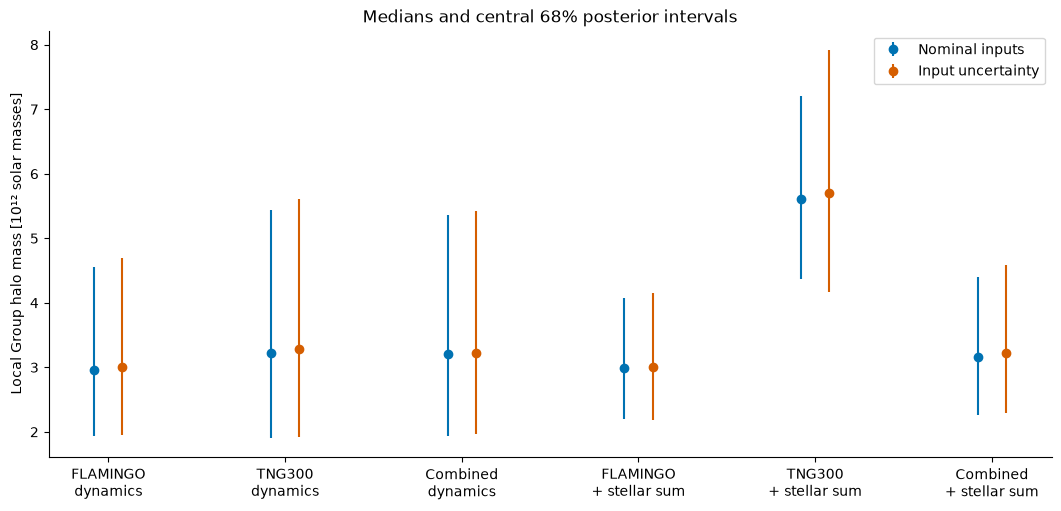

,model,inference_type,16th percentile,Median,84th percentile
0,flamingo_dynamics,nominal,1.94,2.96,4.55
1,flamingo_dynamics,observational_uncertainty,1.95,3.01,4.69
2,flamingo_stellar_sum,nominal,2.19,2.99,4.07
3,flamingo_stellar_sum,observational_uncertainty,2.18,3.01,4.15
4,tng_dynamics,nominal,1.91,3.23,5.43
5,tng_dynamics,observational_uncertainty,1.93,3.28,5.61
6,tng_stellar_sum,nominal,4.36,5.61,7.20
7,tng_stellar_sum,observational_uncertainty,4.17,5.70,7.92
8,combined_dynamics,nominal,1.93,3.21,5.36
9,combined_dynamics,observational_uncertainty,1.97,3.23,5.42


In [5]:
lg = table('local_group/local_group_posterior_summary.csv')
keys = ['flamingo_dynamics','tng_dynamics','combined_dynamics',
        'flamingo_stellar_sum','tng_stellar_sum','combined_stellar_sum']
nominal = lg.query("inference_type == 'nominal'").set_index('model')
mixture = lg.query("inference_type == 'observational_uncertainty'").set_index('model')
assert np.isclose(nominal.loc['tng_stellar_sum','mass_median_msun']/1e12, 5.611565, atol=1e-6)
assert np.max(np.abs(mixture.loc[keys,'log_median']-nominal.loc[keys,'log_median'])) < .009
assert np.isclose(nominal.loc['tng_stellar_sum','log_median']-nominal.loc['flamingo_stellar_sum','log_median'], .27399, atol=1e-5)
fig, ax = plt.subplots(figsize=(10.5, 5), layout='constrained')
for offset, data, label, colour in [(-.08,nominal,'Nominal inputs','#0072B2'),
                                    (.08,mixture,'Input uncertainty','#D55E00')]:
    d = data.loc[keys]
    median = d.mass_median_msun.to_numpy()/1e12
    low = d.mass_q16_msun.to_numpy()/1e12
    high = d.mass_q84_msun.to_numpy()/1e12
    ax.errorbar(np.arange(len(keys))+offset, median,
                yerr=np.vstack([median-low,high-median]), fmt='o', color=colour, label=label)
ax.set_xticks(np.arange(len(keys)), ['FLAMINGO\ndynamics','TNG300\ndynamics','Combined\ndynamics',
                                    'FLAMINGO\n+ stellar sum','TNG300\n+ stellar sum','Combined\n+ stellar sum'])
ax.set(ylabel='Local Group halo mass [10¹² solar masses]', title='Medians and central 68% posterior intervals')
ax.legend();plt.show()
summary = lg[['model','inference_type','mass_q16_msun','mass_median_msun','mass_q84_msun']].copy()
summary[['mass_q16_msun','mass_median_msun','mass_q84_msun']] /= 1e12
summary = summary.rename(columns={'mass_q16_msun':'16th percentile','mass_median_msun':'Median','mass_q84_msun':'84th percentile'})
display(summary.round(2).reset_index(drop=True))

## What the results establish

In the tested morphology and absolute-stellar experiments, inputs that improve within-simulation prediction also reduce cross-simulation robustness. The morphology ablation identifies sensitivity to stellar velocity dispersion, while the stellar-input experiments identify sensitivity to absolute normalization. These findings do not establish that every informative feature transfers poorly or identify a unique physical mechanism. Similar marginal input distributions do not establish that the joint relationship with mass transfers.

The results do not establish which simulation gives the correct Local Group mass. Feedback, resolution, halo finding, cosmology and selection vary together; neither agreement within one simulation nor balanced combined training proves physical accuracy. No consensus Local Group mass is given because of the simulation dependence of the posteriors.

Controlled simulation variants, common finders and stellar apertures, halo-selected parent samples, a third simulation, host-conditioned models and flexible scalar densities remain follow-up experiments. The separate [classifier-mixture notebook](13_classifier_mixture_posteriors.ipynb) is an extension, rather than an additional thesis result.

[Full notebook sequence](00_start_here.ipynb) · [Thesis table and figure map](../docs/thesis_map.ipynb) · [Repository overview](../README.md)